# 00　OFDM 上电初始化 · 时钟 / 位流 / RFDC / 环回 / 本案例自检

`01_OFDM_tx_rx` 的每一格都假设"板卡已经就绪"：LMK 出了 256 MHz 与连续 SYSREF、位流已下载、
RFDC 已初始化、DMA 已认对方向。**断电或重启之后这些全都不成立** —— PYNQ 不会自动下位流，
也不会自动配时钟芯片。本册把这条启动流水线跑一遍，并把 **OFDM** 的发射基带先在离线算一遍
（不碰硬件），确认参数自洽、不削顶、装得进接收窗。

```
  ① SPI      ② 位流 v106     ③ RFDC             ④ 环回自检    ⑤ 本案例基带
  LMK04828 ─▶ 128 位 MM ───▶ 4096 MSPS/NCO ──▶ 波峰因数 ──▶ OFDM 帧 / 频谱 / 相关峰
  PLL2 锁定   C_FRAME_LEN     1000 MHz           < 2.5          离线，不碰硬件
```

| 步骤 | 函数 | 期望 | 不做 / 做错的典型现象 |
|---|---|---|---|
| 1 环境 | `preflight()` | root + 三个时钟脚本 + SPI 节点 | `/dev/mem`、`spidev` 打不开 |
| 2 时钟 | `ensure_clock()` | PLL2 锁定、SYSREF MUX=3 | DMA 有 IOC，但数据全是 0 |
| 3 位流 | `locate_bit()` / `hw_summary()` | MM 位宽 128、`C_FRAME_LEN` = 4194303 | TX 出保持段、DMA 数据是垃圾 |
| 4 RFDC | `open_hardware()` | DAC state=0xF、ADC 使能、NCO 1000 | 星座不转、只有一个点 |
| 5 环回 | `probe()` | 波峰因数 < 2.5 | ≥ 3.4 说明 ADC 只回了 I 路 |
| 6 本案例 | 离线构建 OFDM 突发 | 削顶 0 点、0.352 ms < 16.384 ms | 01 一开跑就削顶，EVM 直接崩 |

本模块案例：**OFDM（1024 点 FFT，QPSK 子载波）**

| 项 | 值 |
|---|---|
| 网格 | N=1024，CP=128，占用 \|k\| ∈ [8, 60]（±15 MHz） |
| 分配 | 导频 14 个（BPSK），数据 92 个（QPSK） |
| 帧结构 | 2 个训练符号 + 6 个数据符号 + 512 点零保护，9728 点 / 帧 |
| 载荷 | 9 帧 × 1024 bit = 9216 bit（网格容量 1104 bit/帧，余下补 0） |
| 抓包落盘 | `mod_01_OFDM.npz`（01 写）→ `mod_02_OFDM.npz`（02 写） |

> `01` / `02` / `03` 各自的第一格也会调同一批函数（能承接就只承接），所以本册**不是硬依赖**。
> 但从冷启动开始，先跑本册能把故障钉在"环境"这一层，而不是等 01 跑到一半再一层层扒。
> OFDM 与五个单载波案例走同一条硬件路径（v106、NCO 1000 MHz、DMA 单次突发环回），
> 区别只在"怎么把比特铺到时频网格上"。


## 1　运行环境自检

### 为什么先自检

后面每一步都直接操作 `/dev/mem`（PL 寄存器）、`spidev`（LMK 的 SPI）和 PYNQ 的 `allocate()`（物理内存），
这三样都要求 **root**。Jupyter 默认就是 root，但如果哪天改成别的用户启动，现象会是
`Permission denied` 而不是"没配好"——先确认身份，能省掉一半误判。

同时确认三个时钟脚本还在：`lmk04828_readback.py`（读回）、`lmk04828_set.py`（写表）、
`sysref_start.py`（起 SYSREF）。它们和 TICS 寄存器表都在 `/home/xilinx/`。

### 路径约定

本册只 import，不修改任何库文件。两个库目录：

- `/home/xilinx/modulation` —— `mod_dsp.py`、`mod_cases.py`、`ofdm_dsp.py`、`ofdm_case.py`、全部 `.npz`；
- `/home/xilinx/qpsk` —— `qpsk_dsp.py`、`qpsk_hw.py`、`qpsk_init.py`、`run_test.py`。

notebook 目录里只放 `.ipynb`，抓包与指标都不落在这里。


In [1]:
import os
import sys

LIB  = "/home/xilinx/modulation"   # mod_dsp / mod_cases / ofdm_* / 全部 .npz
QPSK = "/home/xilinx/qpsk"         # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "OFDM"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import qpsk_init as QI

QI.preflight()      # root、时钟脚本、TICS 表、SPI 节点，一次查完


kernel : 6.12.40-xilinx-g0900176227cc
python : 3.12.3 → /usr/local/share/pynq-venv/bin/python3
uid    : 0
nb dir : /home/xilinx/qpsk
legacy : /home/xilinx/qpsk
  [PASS] 运行身份是 root                              uid=0
  [PASS] 时钟脚本在位 lmk04828_readback.py            /home/xilinx/lmk04828_readback.py
  [PASS] 时钟脚本在位 lmk04828_set.py                 /home/xilinx/lmk04828_set.py
  [PASS] 时钟脚本在位 sysref_start.py                 /home/xilinx/sysref_start.py
  [PASS] 256 MHz 寄存器表在位                         LMK04828_256m.tics.txt

 1　运行环境
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  运行身份是 root                              uid=0
  PASS  时钟脚本在位 lmk04828_readback.py            /home/xilinx/lmk04828_readback.py
  PASS  时钟脚本在位 lmk04828_set.py                 /home/xilinx/lmk04828_set.py
  PASS  时钟脚本在位 sysref_start.py                 /home/xilinx/sysref_start.py
  PASS  256 MHz 寄存器表在位                        

{'PASS': 5, 'FAIL': 0, 'SKIP': 0}

**应该看到**：`[PASS]` 五项，`uid : 0`。

**不对怎么查**：

| 现象 | 处置 |
|---|---|
| `uid ≠ 0` | Jupyter 要以 root 启动，否则后面所有 MMIO 都会失败 |
| 某个脚本 `FAIL` | 从出厂镜像恢复 `/home/xilinx/<脚本>`，或确认路径 |
| `SPI 节点` 找不到（下一节） | `sudo ls /sys/bus/spi/devices/`，检查设备树的 `compatible` |


## 2　时钟：LMK04828 的 PLL2 与连续 SYSREF

### 为什么这是重启后的第一块绊脚石

LMK 是**外部时钟芯片**，寄存器上电后是空的，必须由软件经 SPI 写一遍。它给出两类信号：

- **256 MHz device clock** → RFDC 内部 PLL ×16 → 4096 MSPS 采样时钟；
- **SYSREF** → 多 tile / 多 converter 的确定性延迟对齐。

时钟没出来时，`xrfdc.init()` **不报错**，`tile_status()` 里 `pll=0`、`state=0`，
DAC 不出数、ADC 不搬数；现象正是"DMA 有 IOC，但缓冲里全是 0"。很容易被误判成 DMA 或 DSP 的 bug。

所以判据放在**时钟层**：`R0x183` bit1 = PLL2 数字锁定（主判据），`R0x139[1:0]=3` = SYSREF 连续输出。
本板 19.2 MHz 晶振直接进 PLL2，PLL1 空载，**`PLL1 LD=0` 是正常的**，不要拿它当故障。


In [2]:
clk = QI.ensure_clock()      # 已锁定时 ~0.2 s 返回；未锁会自动写表 + 起 SYSREF


  读回窗口自检通过（3 字节传输，rx[2] = 数据字节）

=== 配置四线 SPI readback ===
  SPI_LOCK 解锁 (R0x1FFD/R0x1FFE=0x00, R0x1FFF=0x53)
  R0x000 = 0x10 (SPI_3WIRE_DIS=1)
  R0x15F 无条件写回 0x13（写前读到 0x13，脏状态下该读数不可信）
  R0x16E = 0x3B (PLL2_LD_MUX=7 readback, TYPE=3 推挽)


  读回可信度检查通过（R0x171=0xAA / R0x172=0x02）
→ PLL2 已锁定、SYSREF 连续输出，跳过写表
  LMK 现状: 读回可信=True  PLL1 LD=0(0x00)  PLL2 LD=1(0x02)  SYSREF MUX=3
  [PASS] LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  [PASS] LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x02
  [PASS] SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  PLL1 LD=0（本板 PLL1 空载，LD=0 正常，不是故障）

 2　时钟
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  PASS  LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x02
  PASS  SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  ----------------------------------------------------------------------------
  PASS 3 / FAIL 0 / SKIP 0


**应该看到**：`PLL2 LD=1`、`SYSREF MUX=3`、三条 `[PASS]`。

写表那条路（`sane=False`、`PLL2 LD=0` 或 `MUX≠3` 时才走）会打印两个脚本的回显，正常。

**判读表**

| 现象 | 含义 | 处置 |
|---|---|---|
| `sane=False` | 读回通路不可信，寄存器值是假的 | 检查 SPI 速率/节点；必要时 `ensure_clock(force=True)` |
| `PLL2 LD=0` | 没有采样时钟 | 看 `sysref_start.py` 回显；确认 `LMK04828_256m.tics.txt` 存在 |
| `MUX≠3` | SYSREF 不是连续输出 | 同上，脚本会重写 `R0x139` |
| `PLL1 LD=0` | PLL1 空载 | **正常**，忽略 |


## 3　位流：`v106/soc.bit`（128 位）+ 同名 `soc.hwh`

### 为什么两者必须成对、同源

`Overlay("soc.bit")` 做两件事：把位流经 FPGA manager 下进 PL；再解析**同名** `.hwh` 得到 IP 清单、
基地址与参数。只有 `.bit` 时加载"成功"，但 `ip_dict` 里没有地址，后面所有 MMIO 都打到错误的地方；
`.hwh` 与 `.bit` 不同源时，基地址和 `C_FRAME_LEN` 全错，现象是"DMA 有 IOC，数据是垃圾"。

**顺序也必须对**：下位流会复位 PL，所以一律"先 Overlay、后 `xrfdc.init()`"。
第 4 节的 `open_hardware()` 就是按这个顺序做的。

### 为什么要看 `Memory Map Data Width`

TX 侧 DMA 每个时钟要吐出 1 个 32 bit 字（256 MHz × 4 B = 1.024 GB/s）。若 MEMORY MAP 数据位宽也是 32 bit，
每条 MM 读都必须在**一个时钟内**回来，密度 100%，DDR 一有刷新抖动就直接变成 DAC 保持段。改成 128 bit 后
每 4 个流时钟才要 1 拍 MM 读，密度降到 25%，余量全给 FIFO 吸收。v106 就是 128 位这一版。


In [3]:
BIT, HWH = QI.locate_bit()       # 默认取 /home/xilinx/jupyter_notebooks/v106/soc.bit
hw = QI.hw_summary(HWH)         # IP 清单 + 两个 DMA 的位宽 + adc2axis 包长


  [PASS] 位流 soc.bit 在位                            /home/xilinx/jupyter_notebooks/v106/soc.bit
  [PASS] 硬件描述 soc.hwh 同源                        /home/xilinx/jupyter_notebooks/v106/soc.hwh
位流 : /home/xilinx/jupyter_notebooks/v106/soc.bit
hwh  : /home/xilinx/jupyter_notebooks/v106/soc.hwh
体积 : 13.2 MB


IP 清单（16）: adc2axis_0, axi_dma_0, axi_dma_1, diver_demo_0, pl_clk_buf_0, rst_rf_clk, smartconnect_0, smartconnect_1, system_ila_0, usp_rf_data_converter_0, xlconcat_0, xlconstant_2, xlslice_2, xpm_cdc_gen_0, xpm_cdc_gen_1, xpm_cdc_gen_2

  IP             方向       MM 数据位宽        流 TDATA 位宽   突发字节       SG
  ----------------------------------------------------------------------------
  axi_dma_0      S2MM/RX  128            32           256        0
  axi_dma_1      MM2S/TX  128            32           64         0

  adc2axis C_FRAME_LEN = 4194303 字（单包上限 16.384 ms）
  [PASS] axi_dma_0 存储器侧位宽 = 128                 C_M_AXI_*_DATA_WIDTH=128
  [PASS] axi_dma_1 存储器侧位宽 = 128                 C_M_AXI_*_DATA_WIDTH=128

 3　位流 / IP
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  位流 soc.bit 在位                            /home/xilinx/jupyter_notebooks/v106/soc.bit
  PASS  硬件描述 soc.hwh 同源                   

**应该看到**（v106 这份 128 位构建）：

```
  IP               方向      MM 数据位宽    流 TDATA 位宽  突发字节   SG
  axi_dma_0        S2MM/RX   128            32             256       0
  axi_dma_1        MM2S/TX   128            32             64        0

  adc2axis C_FRAME_LEN = 4194303 字（单包上限 16.384 ms）
  [PASS] axi_dma_0 存储器侧位宽 = 128
  [PASS] axi_dma_1 存储器侧位宽 = 128
```

**不对怎么查**：

| 现象 | 含义 | 处置 |
|---|---|---|
| `MM 数据位宽 = 32` | 这是旧的 32 位构建 | 换回 128 位位流，或接受 TX 保持段 |
| `没有找到配对的 soc.bit + soc.hwh` | 文件缺失或不同目录 | 放进 `v106/`，或 `export QPSK_BIT=/path/soc.bit` |
| 跑起来 `ip_dict` 为空 | hwh 与 bit 不同名 | 改名成同基名 |


## 4　RFDC 与 NCO：把收发两侧调到同一个频点

### 为什么 NCO 收发两侧必须同频

DAC 数据路径把复基带乘上 $e^{j2\pi f_c t}$ 再取实部（上变频），ADC 反过来乘 $e^{-j2\pi f_c t}$ 再抽取（下变频）。
两侧用**同一个** $f_c=1000$ MHz 时，基带里的信号原样回到基带；两侧差 $\Delta f$，整个星座会以 $\Delta f$ 匀速旋转，
解调前的频偏估计能吃掉一部分，但残余会直接变成 BER。OFDM 对频偏更敏感：子载波间隔只有 250 kHz，
残余频偏会同时产生公共相位（导频可纠）和载波间干扰（纠不了），所以 02 里先校 CFO 再逐子载波均衡。

`open_hardware()` 做的事：Overlay（PL 里已是 v106 就只解析 hwh，不重下）→ 若位流换过则
`xrfdc.deinit/init` → `set_fs_mhz(4096)` → DAC/ADC NCO = 1000 MHz → 按 hwh 参数认 DMA 方向
（不靠 `axi_dma_0/1` 的名字）。

> 本板 `xrfdc` 是自研的**扁平 ctypes 封装**，不是 PYNQ 插件 —— `ol.rfdc` 恒为 `None`，别去找 `RFdc()`。
> `xrfdc.init()` 内含 StartUp，重复调用会把 ADC tile 拖到 `0xC`，所以只在 `is_ready()` 为假时初始化一次。


In [4]:
lb = QI.open_hardware(BIT)      # Overlay（必要时）→ xrfdc init → fs 4096 → NCO 1000 → 认 DMA


  overlay 承接 1070 ms，5 个 IP
  DAC0 NCO 已是 1000.000 MHz，沿用
  ADC0 NCO 已是 1000.000 MHz，沿用
  RF 采样率 4096.0 MSPS → 字率 256.000 MHz
  DAC0 enabled=True state=0xF PLL=1
  ADC0 enabled=True state=0xF PLL=1
  [PASS] xRFDC 已就绪                                 is_ready()=True
  [PASS] DAC0 进入 FULL                               state=0xF
  [PASS] ADC0 已使能                                  enabled=True
  [PASS] TX/RX DMA 已定位                             TX@0x80020000 RX@0x80000000

 4　RFDC / DMA
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  xRFDC 已就绪                                 is_ready()=True
  PASS  DAC0 进入 FULL                               state=0xF
  PASS  ADC0 已使能                                  enabled=True
  PASS  TX/RX DMA 已定位                             TX@0x80020000 RX@0x80000000
  ----------------------------------------------------------------------------
  PASS 4 / FAIL 0 / SKIP 0


**应该看到**：`overlay 载入 … ms`、`DAC0/ADC0 NCO 回读 1000.000 MHz`、
`RF 采样率 4096.0 MSPS → 字率 256.000 MHz`、`DAC0 state=0xF`、`ADC0 enabled=True`，四项 `[PASS]`。

> `state` 是 DAC 的 FIFO 满标志，`init()` 刚返回时是 `0x5`，数据通路起转后才变 `0xF`。
> 本函数会自动等最多 2 s（板上实测 0.1~0.2 s 到位），所以不该看到它一直是 `0x5`。

**不对怎么查**：

| 现象 | 处置 |
|---|---|
| `xRFDC 已就绪 FAIL` | 回第 2 节确认 PLL2 锁定 |
| 等 2 s 仍是 `0x5` / `0x0` | 时钟或 SYSREF 未就绪；或 tile 的 PLL 被关掉 |
| 之后星座不转、只有一个点 | 调 `lb.rf_reinit()`（0.1 s，比重下位流快 20 倍） |


## 5　收发自检：波峰因数

### 为什么用波峰因数而不是"看起来对不对"

本板每次下位流后，ADC 有相当概率**只回 I 通道**（虚部恒 0）。此时收到的是实信号 $s+\bar s$：
包络周期性过零，**帧起点、帧间距、相关峰全都正常**，只有星座和比特全错。这个现象极易被误判成 DSP 有 bug。

判据很干净：干净的单边带 QPSK 包络近似恒定，波峰因数（峰值/rms）≈1.6；双边带污染时 ≥3.4。
`probe()` 发 2 帧 QPSK、抓回、算这个比值；不达标就重跑 `rf_reinit()`，最多 4 次。

> 探针用 **QPSK** 而不是 OFDM：OFDM 本身就是多载波叠加，时域包络起伏天然很大（本案例 PAPR 约 19.5 dB），
> 波峰因数判据会失效。OFDM 的"通道是否干净"由 01/02 的 BER / EVM 直接回答。


In [5]:
cf, x = QI.probe(lb)      # 发 2 帧 QPSK，量波峰因数；不达标会自动 rf_reinit 重试


  自检 0：收 4194299 字，波峰因数 2.08 → 干净
  [PASS] 环回波峰因数 < 2.5                           2.08

 5　收发自检
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  环回波峰因数 < 2.5                           2.08
  ----------------------------------------------------------------------------
  PASS 1 / FAIL 0 / SKIP 0


**应该看到**：`自检 0：收 4194299 字，波峰因数 1.1x~1.6x → 干净`，随后一条
`[PASS] 环回波峰因数 < 2.5`。

若第一次 ≥2.5，会看到它自动 `重跑 RFDC 初始化` 再来一次 —— 这是设计的恢复路径，不是故障。
连续 4 次都 ≥2.5，先查 SMA 环回线和衰减器，再考虑重下位流。


## 6　本案例基带自检：OFDM（1024 点 FFT，QPSK 子载波）

### 为什么在离线先算一遍

第 5 节判的是**通道**，这一节判的是**波形**。四件事必须在碰硬件之前确认：

1. **不削顶**。发射峰值定在 40% 满量程（`mod_cases.PEAK = 0.4`），DAC 是 16 bit。
   OFDM 是多载波叠加，PAPR 天然高（本案例约 19.5 dB），峰值一碰满量程就先削掉最尖的几个采样，
   而 OFDM 的 EVM 对削顶非常敏感 —— 现象会像"整片星座发糊"，追起来很贵。
2. **装得进接收窗**。S2MM 一次只收 `C_FRAME_LEN = 4194303` 字 = **16.384 ms**。
   9 帧突发只有 0.352 ms，占 2.1%，余量很大；但改帧数 / 改 N 之后要重新核。
3. **帧数与比特数对得上**。01 会把这些比特作为真值存进 `.npz`，03 逐比特比对时用的是同一组。
   网格容量 1104 bit/帧，实际载荷 1024 bit/帧，不足部分补 0 且不计入 BER。
4. **同步特征明显**。训练符号是固定种子的已知序列，相关峰必须比噪声底高一个量级，
   否则板上的定时会飘。这里用发送基带先量一次"正常 / 共轭"两条相关曲线。

本节只用 `mod_dsp` / `mod_cases` / `ofdm_dsp` / `ofdm_case`，**不 import pynq、不碰 DMA**，
所以断电重启后单跑这一格也成立。


In [6]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C
import ofdm_dsp as O
import ofdm_case as OC
import qpsk_dsp as D

import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

FS     = lb.fs_word                    # fabric 字率，实测 256 MHz
PKT_MS = 4194303 / FS * 1e3            # 单包接收窗 16.384 ms

const, payload, bb, meta = OC.build()   # 与 01 完全同一段基带（同种子）
n_bit    = meta["n_bits"] * meta["frames"]
peak_lsb = int(np.max(np.abs(bb)) * 32767)
clip     = int(np.sum(np.abs(bb) * 32767 >= 32767))
dur_ms   = len(bb) / FS * 1e3
fill     = 100.0 * meta["n_bits"] / meta["cap_bits"]

print("案例 %s：%d 帧 × %d bit = %d bit（QPSK 网格容量 %d bit/帧）"
      % (meta["name"], meta["frames"], meta["n_bits"], n_bit, meta["cap_bits"]))
print("  N=%d，CP=%d（%.1f%%），符号 %.2f µs，子载波间隔 %.0f kHz"
      % (meta["n_fft"], meta["cp"], 100.0 * meta["cp"] / meta["n_fft"],
         (meta["n_fft"] + meta["cp"]) / FS * 1e6, FS / meta["n_fft"] / 1e3))
print("  占用子载波 %d（导频 %d + 数据 %d），带宽 ±%.1f MHz"
      % (meta["k_used"], meta["k_pilot"], meta["k_data"],
         O.K_MAX * FS / O.N / 1e6))
print("  每帧 %d 点 = %.1f µs，%d 帧突发 %d 点 = %.3f ms"
      % (meta["frame_len"], meta["frame_len"] / FS * 1e6, meta["frames"],
         len(bb), dur_ms))
print("  峰值 %d LSB（%.0f%% 满量程），削顶 %d 点，PAPR %.1f dB"
      % (peak_lsb, 100.0 * meta["peak"], clip, meta["papr_db"]))
print("  网格利用率 %.1f%%（其余补 0，不计入 BER）" % fill)
print()
print("  01 将发送这一段并发回，落盘 %s" % CAP_NPZ)
print("  02 落盘指标 %s" % DEM_NPZ)


案例 OFDM：9 帧 × 1024 bit = 9216 bit（QPSK 网格容量 1104 bit/帧）
  N=1024，CP=128（12.5%），符号 4.50 µs，子载波间隔 250 kHz
  占用子载波 106（导频 14 + 数据 92），带宽 ±15.0 MHz
  每帧 9728 点 = 38.0 µs，9 帧突发 90112 点 = 0.352 ms
  峰值 13106 LSB（40% 满量程），削顶 0 点，PAPR 19.5 dB
  网格利用率 92.8%（其余补 0，不计入 BER）

  01 将发送这一段并发回，落盘 /home/xilinx/modulation/mod_01_OFDM.npz
  02 落盘指标 /home/xilinx/modulation/mod_02_OFDM.npz


**应该看到**：

```
案例 OFDM：9 帧 × 1024 bit = 9216 bit（QPSK 网格容量 1104 bit/帧）
  N=1024，CP=128（12.5%），符号 4.50 µs，子载波间隔 250 kHz
  占用子载波 106（导频 14 + 数据 92），带宽 ±15.0 MHz
  每帧 9728 点 = 38.0 µs，9 帧突发 90112 点 = 0.352 ms
  峰值 13106 LSB（40% 满量程），削顶 0 点，PAPR 19.5 dB
  网格利用率 92.8%（其余补 0，不计入 BER）
```

**不对怎么查**：

| 现象 | 含义 | 处置 |
|---|---|---|
| 削顶点数 > 0 | 峰值超过满量程 | 降 `PEAK`（0.4 → 0.35），或查 `build_burst` 的归一化 |
| 占比 > 60% | 基带太长 | 减帧数或减 `N_SYM`；接收窗是硬上限 16.384 ms |
| PAPR > 22 dB | 训练序列与数据相位凑巧对齐 | 换 `_RNG` 种子重算训练符号；不要靠降峰值硬压 |
| 网格利用率 < 80% | `N_BITS` 相对容量太小 | 调 `N_BITS`，或减 `N_SYM`（容量 = 92×N_SYM×2） |


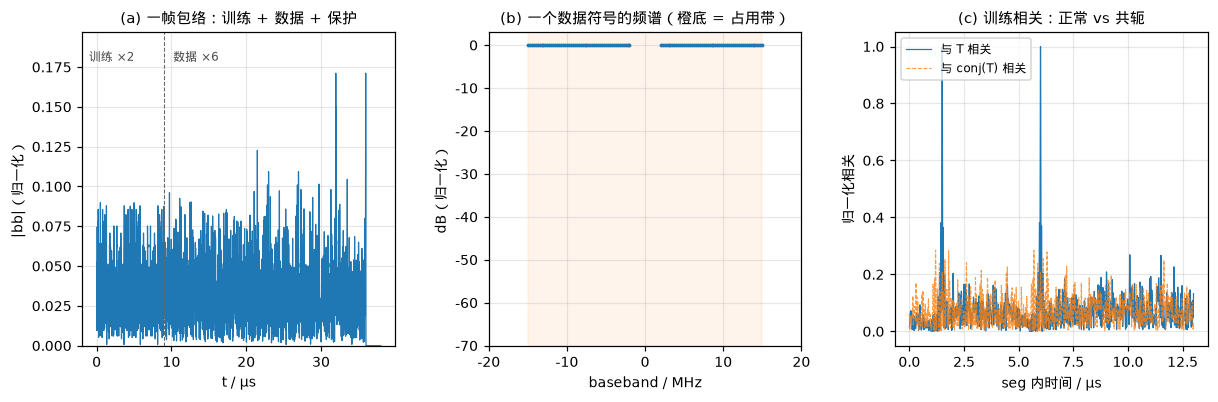

训练相关峰 / 共轭相关峰 = 3.52（发送侧正常应 > 1）


In [7]:
fig = plt.figure(figsize=(13.2, 3.7))
gs = fig.add_gridspec(1, 3, wspace=0.30)

lead = meta["lead"]
ax = fig.add_subplot(gs[0, 0])
seg = np.abs(bb[lead:lead + meta["frame_len"]])
t = np.arange(len(seg)) / FS * 1e6
ax.plot(t, seg, lw=0.8, color="C0")
ax.axvline(O.TRAIN_LEN / FS * 1e6, color="0.4", ls="--", lw=0.7)
ax.set_ylim(0, float(seg.max()) * 1.15)
ax.text(0.02, 0.94, "训练 ×2", transform=ax.transAxes, fontsize=8,
        color="0.3", va="top")
ax.text(0.29, 0.94, "数据 ×%d" % O.N_SYM, transform=ax.transAxes,
        fontsize=8, color="0.3", va="top")
ax.set_xlabel("t / µs"); ax.set_ylabel("|bb|（归一化）")
ax.set_title("(a) 一帧包络：训练 + 数据 + 保护")

ax = fig.add_subplot(gs[0, 1])
s0 = 3                      # 取第 4 个数据符号
st = lead + O.TRAIN_LEN + s0 * O.SYM_LEN + O.CP
X = np.fft.fftshift(np.fft.fft(bb[st:st + O.N]))
f = np.fft.fftshift(np.fft.fftfreq(O.N, 1 / FS))
dB = 20 * np.log10(np.abs(X) + 1e-12)
ax.plot(f / 1e6, dB - dB.max(), ".", ms=3)
ax.axvspan(-O.K_MAX * O.SPACING / 1e6, O.K_MAX * O.SPACING / 1e6,
           color="C1", alpha=0.08)
ax.set_xlim(-20, 20); ax.set_ylim(-70, 3)
ax.set_xlabel("baseband / MHz"); ax.set_ylabel("dB（归一化）")
ax.set_title("(b) 一个数据符号的频谱（橙底 = 占用带）")

ax = fig.add_subplot(gs[0, 2])
seg = bb[lead - 256:lead + 4096]
cn = np.abs(D.xcorr_valid(seg, O.T_TRAIN))
cc = np.abs(D.xcorr_valid(seg, np.conj(O.T_TRAIN)))
i = np.arange(len(cn)) / FS * 1e6
ax.plot(i, cn / cn.max(), lw=0.8, label="与 T 相关")
ax.plot(i, cc / cn.max(), lw=0.7, ls="--", alpha=0.8,
        label="与 conj(T) 相关")   # 同一把尺子，才能看出差 3 倍
ax.set_xlabel("seg 内时间 / µs"); ax.set_ylabel("归一化相关")
ax.set_title("(c) 训练相关：正常 vs 共轭")
ax.legend(loc="upper left")
plt.show()

print("训练相关峰 / 共轭相关峰 = %.2f（发送侧正常应 > 1）"
      % (cn.max() / cc.max()))


**应该看到**：三张图分别是——

- (a) 38 µs 一帧：开头 9 µs 是两段相同训练符号，随后 27 µs 是 6 个数据符号，末尾 2 µs 静默；
- (b) 频谱是**梳状**的：能量只落在 ±15 MHz 内的 106 根 250 kHz 栅格上，带外是噪底；
- (c) 相关曲线在训练符号起点有两个尖峰（间隔 1152 点 = 4.5 µs），正常/共轭两条曲线差 3 倍以上。

(c) 的两个尖峰是同一帧里两个训练符号；帧与帧之间的尖峰间距是 8576 点（38 µs − 4.5 µs）。
02 的 `synchronize()` 用第一个尖峰定帧起点，用两个尖峰的相位差量 CFO。


## 7　汇总

把前六步的判据合成一张表。**全 PASS 再去跑 `01_OFDM_tx_rx.ipynb`。**


In [8]:
def pad(s, w):
    """中文占两列，直接 len() 会让表格歪掉。"""
    return s + " " * max(0, w - sum(2 if ord(ch) > 0x2E80 else 1 for ch in s))


st = lb.status()
rows = [
    ("运行身份 root",                    os.geteuid() == 0),
    ("LMK PLL2 锁定",                    clk["ld2"] == 1),
    ("SYSREF 连续输出 (MUX=3)",          clk["mux"] == 3),
    ("位流 + hwh 配对",                  BIT is not None),
    ("DMA 存储器侧位宽 128",             bool(hw["dmas"]) and all(
                                         i["mm"] == "128" for i in hw["dmas"].values())),
    ("RFDC ready",                       bool(lb.rf_ready)),
    ("DAC0 FULL (state=0xF)",            st["DAC"].get("state") == 0xF),
    ("ADC0 使能",                        st["ADC"].get("enabled") == 1),
    ("环回波峰因数 < %.1f" % QI.CF_CLEAN, cf < QI.CF_CLEAN),
    ("本案例基带无削顶",                  clip == 0),
    ("本案例时长 < 单包 %.1f ms" % PKT_MS, dur_ms < PKT_MS),
    ("网格利用率 ≥ 80%",                  fill >= 80.0),
    ("PAPR ≤ 22 dB",                      meta["papr_db"] <= 22.0),
]

print("%s %s" % (pad("项目", 34), "结果"))
print("-" * 48)
for name, ok in rows:
    print("%s %s" % (pad(name, 34), "PASS" if ok else "FAIL"))
bad = [n for n, ok in rows if not ok]
print("-" * 48)
if bad:
    print("总结：未通过 %s —— 按上面各节的判读表处置" % "、".join(bad))
else:
    print("总结：全部通过 —— 下一步打开 01_OFDM_tx_rx.ipynb")

print()
print("  此刻 PL 里是 v106（128 位），RF %.0f MSPS，字率 %.0f MHz，DAC/ADC NCO = %.0f MHz"
      % (lb.fs_rf, lb.fs_word / 1e6, QI.NCO_MHZ))
print("  本案例 OFDM：%d 点 = %.3f ms，峰值 %d LSB，削顶 %d 点，PAPR %.1f dB"
      % (len(bb), dur_ms, peak_lsb, clip, meta["papr_db"]))

# 收尾：两颗 DMA 都 stop，DAC 停在最后一个字上（直流），不留后台搬运
for _ch in (getattr(lb, "TX", None), getattr(lb, "RX", None)):
    try:
        _ch.stop()
    except Exception:
        pass
print("\n  DMA 已 stop，DAC 停在最后一个字上（直流）。")


项目                               结果
------------------------------------------------
运行身份 root                      PASS
LMK PLL2 锁定                      PASS
SYSREF 连续输出 (MUX=3)            PASS
位流 + hwh 配对                    PASS
DMA 存储器侧位宽 128               PASS
RFDC ready                         PASS
DAC0 FULL (state=0xF)              PASS
ADC0 使能                          PASS
环回波峰因数 < 2.5                 PASS
本案例基带无削顶                   PASS
本案例时长 < 单包 16.4 ms          PASS
网格利用率 ≥ 80%                   PASS
PAPR ≤ 22 dB                       PASS
------------------------------------------------
总结：全部通过 —— 下一步打开 01_OFDM_tx_rx.ipynb

  此刻 PL 里是 v106（128 位），RF 4096 MSPS，字率 256 MHz，DAC/ADC NCO = 1000 MHz
  本案例 OFDM：90112 点 = 0.352 ms，峰值 13106 LSB，削顶 0 点，PAPR 19.5 dB

  DMA 已 stop，DAC 停在最后一个字上（直流）。


---

## 下一步

| notebook | 做什么 | 需要本册先跑过吗 |
|---|---|---|
| `01_OFDM_tx_rx` | 生成 OFDM 突发 → DMA 发 → 立即收 → 存 `mod_01_OFDM.npz` | 不需要（第 3 节会自己做同一套初始化，本册跑过时只承接） |
| `02_OFDM_demod` | 从 npz 做同步/信道估计/均衡 → 存 `mod_02_OFDM.npz` | 不需要（纯离线） |
| `03_OFDM_verify` | 真值 vs 解调逐比特比对，BER / EVM / 余量 / CFO | 不需要（纯离线） |

## 中断 / 重启后的最短恢复路径

```python
import sys; sys.path.insert(0, "/home/xilinx/qpsk")
import qpsk_init as QI
QI.ensure_clock()          # 时钟
BIT, _ = QI.locate_bit()   # 位流（v106）
lb = QI.open_hardware(BIT) # RFDC + DMA + NCO
QI.probe(lb)               # 环回自检
```
四行以内，10 秒左右。之后 `lb` 可以直接交给 `lb.loop(words)` 收发。
